<a href="https://colab.research.google.com/github/abdelrhman2006-rgb/Movie_Popularity_Prediction/blob/main/Movie_Popularity_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

%pip install -q pyspark


In [2]:

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MoviePopularityPrediction")
    .master("local[*]")
    .getOrCreate()
)

print("Spark Version:", spark.version)
print("Spark Session Created Successfully!")


Spark Version: 4.0.5
Spark Session Created Successfully!


In [5]:

import os
import zipfile

zip_path = "/content/archive.zip"

print("File Size:", os.path.getsize(zip_path), "bytes")
print("Is ZIP:", zipfile.is_zipfile(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files:", z.namelist())
    print("Corrupted File:", z.testzip())


File Size: 10366006 bytes
Is ZIP: True
Files: ['tmdb_5000_credits.csv', 'tmdb_5000_movies.csv']
Corrupted File: tmdb_5000_credits.csv


In [7]:



# Step 1: Import Libraries
from pyspark.sql import SparkSession

# Step 2: Create Spark Session
spark = SparkSession.builder \
    .appName("MoviePopularityPrediction") \
    .master("local[*]") \
    .getOrCreate()

# Step 3: Load Movies Dataset
movies_df = spark.read.csv(
    "/content/tmdb_5000_movies.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape='"'
)

# Step 4: Load Credits Dataset
credits_df = spark.read.csv(
    "/content/tmdb_5000_credits.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape='"'
)

# Step 5: Check Data
print("Movies:", movies_df.count())
print("Credits:", credits_df.count())

print("First 5 Movies:")
movies_df.select(
    "title",
    "budget",
    "popularity",
    "runtime"
).show(5, truncate=False)


Movies: 4803
Credits: 4803
First 5 Movies:
+----------------------------------------+---------+----------+-------+
|title                                   |budget   |popularity|runtime|
+----------------------------------------+---------+----------+-------+
|Avatar                                  |237000000|150.437577|162.0  |
|Pirates of the Caribbean: At World's End|300000000|139.082615|169.0  |
|Spectre                                 |245000000|107.376788|148.0  |
|The Dark Knight Rises                   |250000000|112.31295 |165.0  |
|John Carter                             |260000000|43.926995 |132.0  |
+----------------------------------------+---------+----------+-------+
only showing top 5 rows


In [8]:

movies_df.select(
    "title",
    "budget",
    "popularity",
    "runtime",
    "release_date"
).show(5, truncate=False)


+----------------------------------------+---------+----------+-------+------------+
|title                                   |budget   |popularity|runtime|release_date|
+----------------------------------------+---------+----------+-------+------------+
|Avatar                                  |237000000|150.437577|162.0  |2009-12-10  |
|Pirates of the Caribbean: At World's End|300000000|139.082615|169.0  |2007-05-19  |
|Spectre                                 |245000000|107.376788|148.0  |2015-10-26  |
|The Dark Knight Rises                   |250000000|112.31295 |165.0  |2012-07-16  |
|John Carter                             |260000000|43.926995 |132.0  |2012-03-07  |
+----------------------------------------+---------+----------+-------+------------+
only showing top 5 rows


In [9]:

movies_df.printSchema()

print("Total Rows:", movies_df.count())
print("Total Columns:", len(movies_df.columns))

print("Column Names:")
print(movies_df.columns)


root
 |-- budget: integer (nullable = true)
 |-- genres: string (nullable = true)
 |-- homepage: string (nullable = true)
 |-- id: integer (nullable = true)
 |-- keywords: string (nullable = true)
 |-- original_language: string (nullable = true)
 |-- original_title: string (nullable = true)
 |-- overview: string (nullable = true)
 |-- popularity: double (nullable = true)
 |-- production_companies: string (nullable = true)
 |-- production_countries: string (nullable = true)
 |-- release_date: date (nullable = true)
 |-- revenue: long (nullable = true)
 |-- runtime: double (nullable = true)
 |-- spoken_languages: string (nullable = true)
 |-- status: string (nullable = true)
 |-- tagline: string (nullable = true)
 |-- title: string (nullable = true)
 |-- vote_average: double (nullable = true)
 |-- vote_count: integer (nullable = true)

Total Rows: 4803
Total Columns: 20
Column Names:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'po

In [10]:

from pyspark.sql import functions as F

missing_values = movies_df.select([
    F.sum(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in movies_df.columns
])

missing_values.show(vertical=True, truncate=False)


-RECORD 0--------------------
 budget               | 0    
 genres               | 0    
 homepage             | 3091 
 id                   | 0    
 keywords             | 0    
 original_language    | 0    
 original_title       | 0    
 overview             | 4    
 popularity           | 0    
 production_companies | 0    
 production_countries | 0    
 release_date         | 1    
 revenue              | 0    
 runtime              | 2    
 spoken_languages     | 0    
 status               | 0    
 tagline              | 844  
 title                | 0    
 vote_average         | 0    
 vote_count           | 0    



In [11]:

total_rows = movies_df.count()

unique_movies = movies_df.select("id").distinct().count()

duplicates = total_rows - unique_movies

print("Total Movies:", total_rows)
print("Unique Movie IDs:", unique_movies)
print("Duplicate IDs:", duplicates)


Total Movies: 4803
Unique Movie IDs: 4803
Duplicate IDs: 0


In [12]:

movies_df.createOrReplaceTempView("movies")

spark.sql("""
    SELECT
        title,
        popularity,
        budget
    FROM movies
    WHERE popularity IS NOT NULL
    ORDER BY popularity DESC
    LIMIT 10
""").show(truncate=False)


+------------------------------------------------------+----------+---------+
|title                                                 |popularity|budget   |
+------------------------------------------------------+----------+---------+
|Minions                                               |875.581305|74000000 |
|Interstellar                                          |724.247784|165000000|
|Deadpool                                              |514.569956|58000000 |
|Guardians of the Galaxy                               |481.098624|170000000|
|Mad Max: Fury Road                                    |434.278564|150000000|
|Jurassic World                                        |418.708552|150000000|
|Pirates of the Caribbean: The Curse of the Black Pearl|271.972889|140000000|
|Dawn of the Planet of the Apes                        |243.791743|170000000|
|The Hunger Games: Mockingjay - Part 1                 |206.227151|125000000|
|Big Hero 6                                            |203.7345

In [13]:

# Step 2.1: Dataset Information

print("Total Movies:", movies_df.count())
print("Total Columns:", len(movies_df.columns))

print("\nDataset Schema:")
movies_df.printSchema()

print("\nFirst 5 Movies:")
movies_df.select(
    "title",
    "budget",
    "popularity",
    "runtime",
    "release_date"
).show(5, truncate=False)


Total Movies: 4803
Total Columns: 20

Dataset Schema:
root
 |-- budget: integer (nullable = true)
 |-- genres: string (nullable = true)
 |-- homepage: string (nullable = true)
 |-- id: integer (nullable = true)
 |-- keywords: string (nullable = true)
 |-- original_language: string (nullable = true)
 |-- original_title: string (nullable = true)
 |-- overview: string (nullable = true)
 |-- popularity: double (nullable = true)
 |-- production_companies: string (nullable = true)
 |-- production_countries: string (nullable = true)
 |-- release_date: date (nullable = true)
 |-- revenue: long (nullable = true)
 |-- runtime: double (nullable = true)
 |-- spoken_languages: string (nullable = true)
 |-- status: string (nullable = true)
 |-- tagline: string (nullable = true)
 |-- title: string (nullable = true)
 |-- vote_average: double (nullable = true)
 |-- vote_count: integer (nullable = true)


First 5 Movies:
+----------------------------------------+---------+----------+-------+------------

In [14]:

from pyspark.sql import functions as F

# Count missing values in each column
missing_values = movies_df.select([
    F.sum(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in movies_df.columns
])

print("Missing Values:")
missing_values.show(vertical=True, truncate=False)


Missing Values:
-RECORD 0--------------------
 budget               | 0    
 genres               | 0    
 homepage             | 3091 
 id                   | 0    
 keywords             | 0    
 original_language    | 0    
 original_title       | 0    
 overview             | 4    
 popularity           | 0    
 production_companies | 0    
 production_countries | 0    
 release_date         | 1    
 revenue              | 0    
 runtime              | 2    
 spoken_languages     | 0    
 status               | 0    
 tagline              | 844  
 title                | 0    
 vote_average         | 0    
 vote_count           | 0    



In [15]:

# Check duplicate movie IDs
total_movies = movies_df.count()

unique_movies = movies_df.select("id").distinct().count()

duplicate_count = total_movies - unique_movies

print("Total Movies:", total_movies)
print("Unique Movies:", unique_movies)
print("Duplicate IDs:", duplicate_count)


Total Movies: 4803
Unique Movies: 4803
Duplicate IDs: 0


In [16]:

# Create working DataFrame
clean_df = movies_df

# Remove duplicate movie IDs
clean_df = clean_df.dropDuplicates(["id"])

print("Rows after removing duplicates:", clean_df.count())


Rows after removing duplicates: 4803


In [17]:

# Convert important columns to numeric types
clean_df = (
    clean_df
    .withColumn("budget", F.col("budget").cast("double"))
    .withColumn("popularity", F.col("popularity").cast("double"))
    .withColumn("runtime", F.col("runtime").cast("double"))
)

# Remove rows with missing target values
clean_df = clean_df.dropna(subset=["popularity"])

# Keep valid popularity scores
clean_df = clean_df.filter(
    F.col("popularity") >= 0
)

# Replace invalid budget values with NULL
clean_df = clean_df.withColumn(
    "budget",
    F.when(F.col("budget") > 0, F.col("budget"))
)

# Replace invalid runtime values with NULL
clean_df = clean_df.withColumn(
    "runtime",
    F.when(F.col("runtime") > 0, F.col("runtime"))
)

print("Rows after cleaning:", clean_df.count())


Rows after cleaning: 4803


In [18]:

# Convert release_date to Date
clean_df = clean_df.withColumn(
    "release_date",
    F.to_date(F.col("release_date"), "yyyy-MM-dd")
)

# Extract release year
clean_df = clean_df.withColumn(
    "release_year",
    F.year(F.col("release_date"))
)

# Display results
clean_df.select(
    "title",
    "release_date",
    "release_year"
).show(10, truncate=False)


+------------------------------------------------------+------------+------------+
|title                                                 |release_date|release_year|
+------------------------------------------------------+------------+------------+
|Four Rooms                                            |1995-12-09  |1995        |
|Star Wars                                             |1977-05-25  |1977        |
|Finding Nemo                                          |2003-05-30  |2003        |
|Forrest Gump                                          |1994-07-06  |1994        |
|American Beauty                                       |1999-09-15  |1999        |
|Dancer in the Dark                                    |2000-05-17  |2000        |
|The Fifth Element                                     |1997-05-07  |1997        |
|Metropolis                                            |1927-01-10  |1927        |
|My Life Without Me                                    |2003-03-07  |2003        |
|Pir

In [19]:

print("Original Movies:", movies_df.count())
print("Cleaned Movies:", clean_df.count())

print("\nCleaned Dataset Schema:")
clean_df.printSchema()

print("\nCleaned Dataset Preview:")
clean_df.select(
    "title",
    "budget",
    "popularity",
    "runtime",
    "release_year"
).show(10, truncate=False)


Original Movies: 4803
Cleaned Movies: 4803

Cleaned Dataset Schema:
root
 |-- budget: double (nullable = true)
 |-- genres: string (nullable = true)
 |-- homepage: string (nullable = true)
 |-- id: integer (nullable = true)
 |-- keywords: string (nullable = true)
 |-- original_language: string (nullable = true)
 |-- original_title: string (nullable = true)
 |-- overview: string (nullable = true)
 |-- popularity: double (nullable = true)
 |-- production_companies: string (nullable = true)
 |-- production_countries: string (nullable = true)
 |-- release_date: date (nullable = true)
 |-- revenue: long (nullable = true)
 |-- runtime: double (nullable = true)
 |-- spoken_languages: string (nullable = true)
 |-- status: string (nullable = true)
 |-- tagline: string (nullable = true)
 |-- title: string (nullable = true)
 |-- vote_average: double (nullable = true)
 |-- vote_count: integer (nullable = true)
 |-- release_year: integer (nullable = true)


Cleaned Dataset Preview:
+---------------

In [20]:

from pyspark.sql import functions as F

# Check missing values after cleaning
important_columns = [
    "budget",
    "runtime",
    "popularity",
    "release_year"
]

clean_df.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in important_columns
]).show()


+------+-------+----------+------------+
|budget|runtime|popularity|release_year|
+------+-------+----------+------------+
|  1037|     37|         0|           1|
+------+-------+----------+------------+



In [21]:

# Remove rows with missing release year
clean_df = clean_df.dropna(subset=["release_year"])

print("Movies after cleaning:", clean_df.count())


Movies after cleaning: 4802


In [22]:

# Split dataset into training and testing
train_df, test_df = clean_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training Movies:", train_df.count())
print("Testing Movies:", test_df.count())


Training Movies: 3905
Testing Movies: 897


In [23]:

from pyspark.ml.feature import Imputer

# Create Imputer
imputer = Imputer(
    inputCols=["budget", "runtime"],
    outputCols=["budget_imputed", "runtime_imputed"],
    strategy="median"
)

# Learn median values from training data
imputer_model = imputer.fit(train_df)

# Apply the same imputation to both datasets
train_df = imputer_model.transform(train_df)
test_df = imputer_model.transform(test_df)

print("Imputation Completed Successfully!")


Imputation Completed Successfully!


In [24]:

from pyspark.sql import functions as F

for name, df in [
    ("Training", train_df),
    ("Testing", test_df)
]:
    print(name, "Missing Values:")

    df.select([
        F.sum(
            F.when(F.col(c).isNull(), 1).otherwise(0)
        ).alias(c)
        for c in ["budget_imputed", "runtime_imputed"]
    ]).show()


Training Missing Values:
+--------------+---------------+
|budget_imputed|runtime_imputed|
+--------------+---------------+
|             0|              0|
+--------------+---------------+

Testing Missing Values:
+--------------+---------------+
|budget_imputed|runtime_imputed|
+--------------+---------------+
|             0|              0|
+--------------+---------------+



In [25]:

train_df.select(
    "title",
    "budget",
    "budget_imputed",
    "runtime",
    "runtime_imputed",
    "popularity"
).show(10, truncate=False)


+-------------------------------------------------+------+--------------+-------+---------------+----------+
|title                                            |budget|budget_imputed|runtime|runtime_imputed|popularity|
+-------------------------------------------------+------+--------------+-------+---------------+----------+
|The Blood of My Brother: A Story of Death in Iraq|NULL  |2.3E7         |90.0   |90.0           |0.005256  |
|Iguana                                           |NULL  |2.3E7         |88.0   |88.0           |0.214704  |
|Sparkler                                         |NULL  |2.3E7         |96.0   |96.0           |0.547654  |
|Harrison Montgomery                              |NULL  |2.3E7         |NULL   |104.0          |0.006943  |
|Gory Gory Hallelujah                             |NULL  |2.3E7         |NULL   |104.0          |0.033883  |
|Diamond Ruff                                     |NULL  |2.3E7         |NULL   |104.0          |0.165257  |
|Childless         

In [26]:

# Step 3.1: Dataset Overview

print("Total Movies:", clean_df.count())
print("Total Columns:", len(clean_df.columns))

clean_df.select(
    "title",
    "budget",
    "popularity",
    "runtime",
    "release_year"
).show(10, truncate=False)


Total Movies: 4802
Total Columns: 21
+------------------------------------------------------+---------+----------+-------+------------+
|title                                                 |budget   |popularity|runtime|release_year|
+------------------------------------------------------+---------+----------+-------+------------+
|Four Rooms                                            |4000000.0|22.87623  |98.0   |1995        |
|Star Wars                                             |1.1E7    |126.393695|121.0  |1977        |
|Finding Nemo                                          |9.4E7    |85.688789 |100.0  |2003        |
|Forrest Gump                                          |5.5E7    |138.133331|142.0  |1994        |
|American Beauty                                       |1.5E7    |80.878605 |122.0  |1999        |
|Dancer in the Dark                                    |1.28E7   |22.022228 |140.0  |2000        |
|The Fifth Element                                     |9.0E7    |109.52

In [27]:

# Descriptive Statistics

clean_df.select(
    "budget",
    "popularity",
    "runtime",
    "release_year"
).describe().show()


+-------+--------------------+------------------+------------------+------------------+
|summary|              budget|        popularity|           runtime|      release_year|
+-------+--------------------+------------------+------------------+------------------+
|  count|                3766|              4802|              4766|              4802|
|   mean|3.7042837631704725E7|21.496776285922532|107.66072177926983|2002.4687630154103|
| stddev| 4.264651443559049E7| 31.81845093512269|20.749423876587542|12.414354076575139|
|    min|                 1.0|           3.72E-4|              14.0|              1916|
|    max|               3.8E8|        875.581305|             338.0|              2017|
+-------+--------------------+------------------+------------------+------------------+



In [28]:

# Create SQL View
clean_df.createOrReplaceTempView("movies_clean")

print("SQL View Created Successfully!")


SQL View Created Successfully!


In [29]:

top_movies = spark.sql("""
    SELECT
        title,
        popularity,
        budget,
        release_year
    FROM movies_clean
    ORDER BY popularity DESC
    LIMIT 10
""")

top_movies.show(truncate=False)


+------------------------------------------------------+----------+------+------------+
|title                                                 |popularity|budget|release_year|
+------------------------------------------------------+----------+------+------------+
|Minions                                               |875.581305|7.4E7 |2015        |
|Interstellar                                          |724.247784|1.65E8|2014        |
|Deadpool                                              |514.569956|5.8E7 |2016        |
|Guardians of the Galaxy                               |481.098624|1.7E8 |2014        |
|Mad Max: Fury Road                                    |434.278564|1.5E8 |2015        |
|Jurassic World                                        |418.708552|1.5E8 |2015        |
|Pirates of the Caribbean: The Curse of the Black Pearl|271.972889|1.4E8 |2003        |
|Dawn of the Planet of the Apes                        |243.791743|1.7E8 |2014        |
|The Hunger Games: Mockingjay - 

In [30]:

yearly_popularity = spark.sql("""
    SELECT
        release_year,
        COUNT(*) AS total_movies,
        ROUND(AVG(popularity), 2) AS avg_popularity
    FROM movies_clean
    WHERE release_year IS NOT NULL
    GROUP BY release_year
    ORDER BY release_year
""")

yearly_popularity.show(20)


+------------+------------+--------------+
|release_year|total_movies|avg_popularity|
+------------+------------+--------------+
|        1916|           1|          3.23|
|        1925|           1|          0.79|
|        1927|           1|         32.35|
|        1929|           2|           1.4|
|        1930|           1|          8.48|
|        1932|           1|           1.2|
|        1933|           2|          1.28|
|        1934|           1|         11.87|
|        1935|           1|           3.9|
|        1936|           2|         15.62|
|        1937|           2|          42.1|
|        1938|           2|          1.96|
|        1939|           3|         42.89|
|        1940|           5|         20.09|
|        1941|           1|           7.7|
|        1942|           2|         45.69|
|        1944|           2|          0.58|
|        1945|           4|          5.02|
|        1946|           3|         19.62|
|        1947|           3|          4.49|
+----------

In [31]:

from pyspark.sql import functions as F

movie_stats = clean_df.agg(
    F.count("*").alias("Total_Movies"),
    F.round(F.avg("popularity"), 2).alias("Avg_Popularity"),
    F.round(F.avg("budget"), 2).alias("Avg_Budget"),
    F.round(F.avg("runtime"), 2).alias("Avg_Runtime")
)

movie_stats.show(truncate=False)


+------------+--------------+-------------+-----------+
|Total_Movies|Avg_Popularity|Avg_Budget   |Avg_Runtime|
+------------+--------------+-------------+-----------+
|4802        |21.5          |3.704283763E7|107.66     |
+------------+--------------+-------------+-----------+



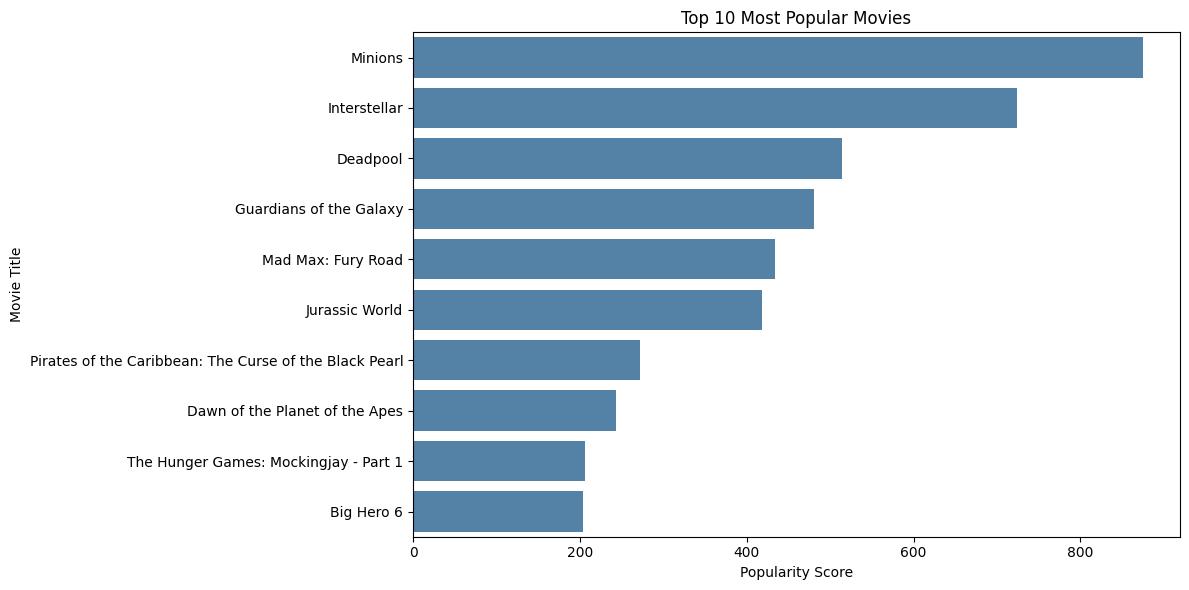

In [32]:

import matplotlib.pyplot as plt
import seaborn as sns

# Convert Spark result to Pandas
top_movies_pd = top_movies.toPandas()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_movies_pd,
    x="popularity",
    y="title",
    color="steelblue"
)

plt.title("Top 10 Most Popular Movies")
plt.xlabel("Popularity Score")
plt.ylabel("Movie Title")

plt.tight_layout()
plt.show()


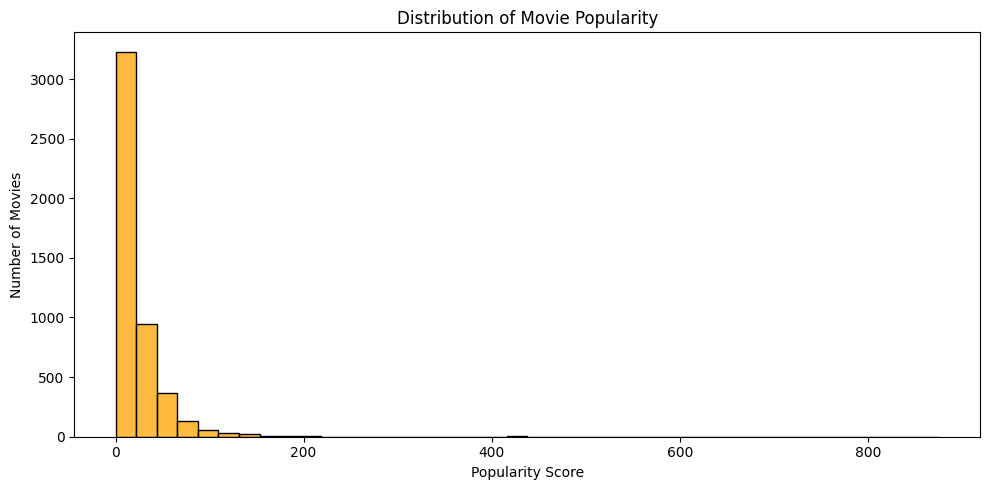

In [33]:

popularity_pd = clean_df.select(
    "popularity"
).toPandas()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=popularity_pd,
    x="popularity",
    bins=40,
    color="orange"
)

plt.title("Distribution of Movie Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()


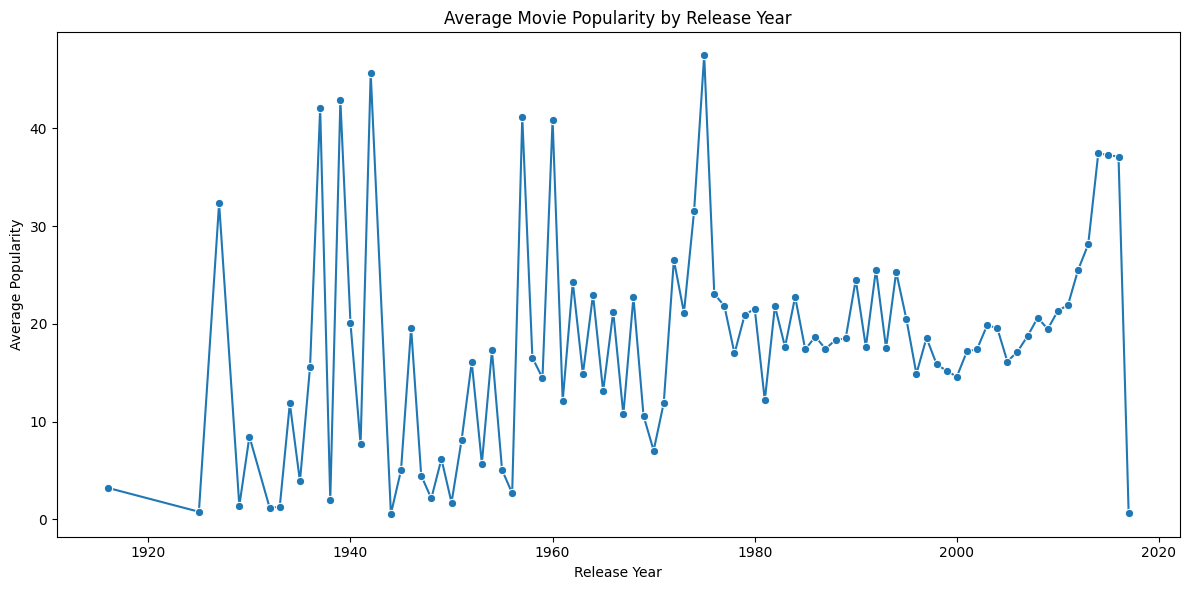

In [34]:

yearly_pd = yearly_popularity.toPandas()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_pd,
    x="release_year",
    y="avg_popularity",
    marker="o"
)

plt.title("Average Movie Popularity by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Average Popularity")

plt.tight_layout()
plt.show()


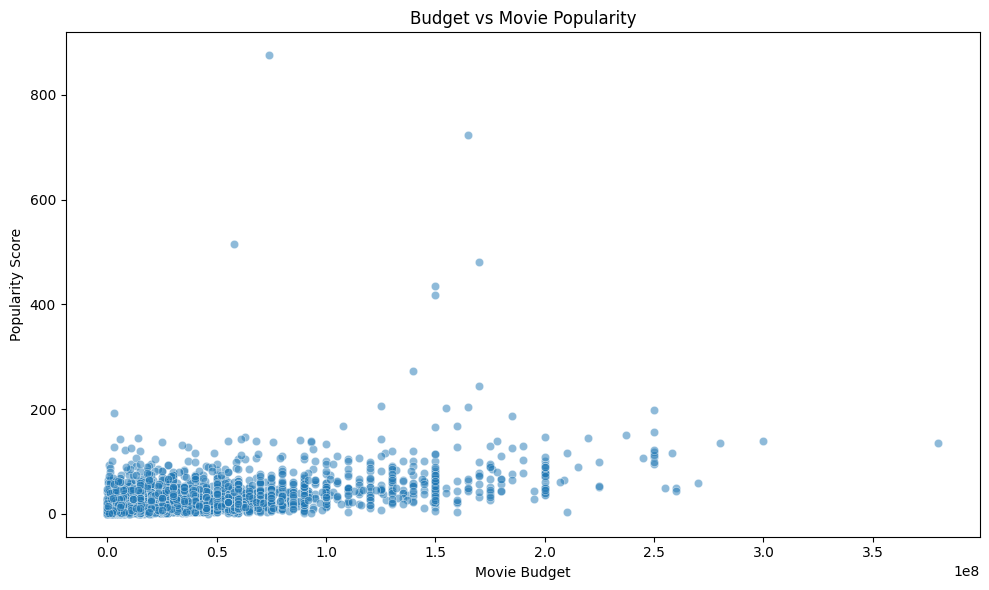

In [35]:

budget_popularity_pd = clean_df.select(
    "budget",
    "popularity"
).dropna().toPandas()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=budget_popularity_pd,
    x="budget",
    y="popularity",
    alpha=0.5
)

plt.title("Budget vs Movie Popularity")
plt.xlabel("Movie Budget")
plt.ylabel("Popularity Score")

plt.tight_layout()
plt.show()


In [36]:

correlation = clean_df.stat.corr(
    "budget",
    "popularity"
)

print("Budget-Popularity Correlation:", correlation)


Budget-Popularity Correlation: 0.5053644352941858


In [37]:

# Step 4.1: Import ML Libraries

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

print("ML Libraries Imported Successfully!")


ML Libraries Imported Successfully!


In [38]:

# Define input features
feature_cols = [
    "budget_imputed",
    "runtime_imputed",
    "release_year"
]

# Create Feature Vector
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features",
    handleInvalid="error"
)

# Prepare Training and Testing Data
train_ml = assembler.transform(train_df)
test_ml = assembler.transform(test_df)

# Preview
train_ml.select(
    "title",
    "features",
    "popularity"
).show(5, truncate=False)


+-------------------------------------------------+--------------------+----------+
|title                                            |features            |popularity|
+-------------------------------------------------+--------------------+----------+
|The Blood of My Brother: A Story of Death in Iraq|[2.3E7,90.0,2005.0] |0.005256  |
|Iguana                                           |[2.3E7,88.0,1988.0] |0.214704  |
|Sparkler                                         |[2.3E7,96.0,1999.0] |0.547654  |
|Harrison Montgomery                              |[2.3E7,104.0,2008.0]|0.006943  |
|Gory Gory Hallelujah                             |[2.3E7,104.0,2003.0]|0.033883  |
+-------------------------------------------------+--------------------+----------+
only showing top 5 rows


In [39]:

# Create Linear Regression Model
lr = LinearRegression(
    featuresCol="features",
    labelCol="popularity",
    predictionCol="prediction",
    maxIter=100,
    regParam=0.1
)

# Train Model
lr_model = lr.fit(train_ml)

# Make Predictions
lr_predictions = lr_model.transform(test_ml)

# Show Predictions
lr_predictions.select(
    "title",
    "popularity",
    "prediction"
).show(10, truncate=False)


+-----------------------------------------------------+----------+------------------+
|title                                                |popularity|prediction        |
+-----------------------------------------------------+----------+------------------+
|Short Cut to Nirvana: Kumbh Mela                     |0.004998  |13.604711040171907|
|The Outrageous Sophie Tucker                         |0.021419  |16.46895646834804 |
|Rise of the Entrepreneur: The Search for a Better Way|0.052942  |17.919308425032   |
|Alleluia! The Devil's Carnival                       |0.674398  |18.09331072257916 |
|The Widow of Saint-Pierre                            |1.780065  |18.151644298885913|
|The Bridge of San Luis Rey                           |0.515677  |19.95000085066414 |
|The Crocodile Hunter: Collision Course               |1.714972  |14.337178715552199|
|Love's Abiding Joy                                   |1.128559  |14.141301326890016|
|Double Take                                          

In [40]:

# Evaluation Metrics
evaluator_rmse = RegressionEvaluator(
    labelCol="popularity",
    predictionCol="prediction",
    metricName="rmse"
)

evaluator_mae = RegressionEvaluator(
    labelCol="popularity",
    predictionCol="prediction",
    metricName="mae"
)

evaluator_r2 = RegressionEvaluator(
    labelCol="popularity",
    predictionCol="prediction",
    metricName="r2"
)

# Evaluate Linear Regression
lr_rmse = evaluator_rmse.evaluate(lr_predictions)
lr_mae = evaluator_mae.evaluate(lr_predictions)
lr_r2 = evaluator_r2.evaluate(lr_predictions)

print("Linear Regression Results")
print("RMSE:", lr_rmse)
print("MAE:", lr_mae)
print("R2:", lr_r2)


Linear Regression Results
RMSE: 23.77608666617998
MAE: 14.290815509237554
R2: 0.26056574977707825


In [41]:

# Create Random Forest Model
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="popularity",
    predictionCol="prediction",
    numTrees=100,
    maxDepth=8,
    seed=42
)

# Train Random Forest
rf_model = rf.fit(train_ml)

# Make Predictions
rf_predictions = rf_model.transform(test_ml)

# Show Predictions
rf_predictions.select(
    "title",
    "popularity",
    "prediction"
).show(10, truncate=False)


+-----------------------------------------------------+----------+------------------+
|title                                                |popularity|prediction        |
+-----------------------------------------------------+----------+------------------+
|Short Cut to Nirvana: Kumbh Mela                     |0.004998  |6.398452816683094 |
|The Outrageous Sophie Tucker                         |0.021419  |10.646730608076538|
|Rise of the Entrepreneur: The Search for a Better Way|0.052942  |12.322676606660423|
|Alleluia! The Devil's Carnival                       |0.674398  |10.099727024040925|
|The Widow of Saint-Pierre                            |1.780065  |9.576929641863355 |
|The Bridge of San Luis Rey                           |0.515677  |11.241430322644762|
|The Crocodile Hunter: Collision Course               |1.714972  |6.280056536019004 |
|Love's Abiding Joy                                   |1.128559  |6.328455473007236 |
|Double Take                                          

In [42]:

# Evaluate Random Forest
rf_rmse = evaluator_rmse.evaluate(rf_predictions)
rf_mae = evaluator_mae.evaluate(rf_predictions)
rf_r2 = evaluator_r2.evaluate(rf_predictions)

print("Random Forest Results")
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)
print("R2:", rf_r2)


Random Forest Results
RMSE: 23.973631894472895
MAE: 13.273756671789124
R2: 0.2482274257146081


In [43]:

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "RMSE": [lr_rmse, rf_rmse],
    "MAE": [lr_mae, rf_mae],
    "R2": [lr_r2, rf_r2]
})

print("Model Comparison:")
display(results.round(4))


Model Comparison:


,Model,RMSE,MAE,R2
0,Linear Regression,23.7761,14.2908,0.2606
1,Random Forest,23.9736,13.2738,0.2482


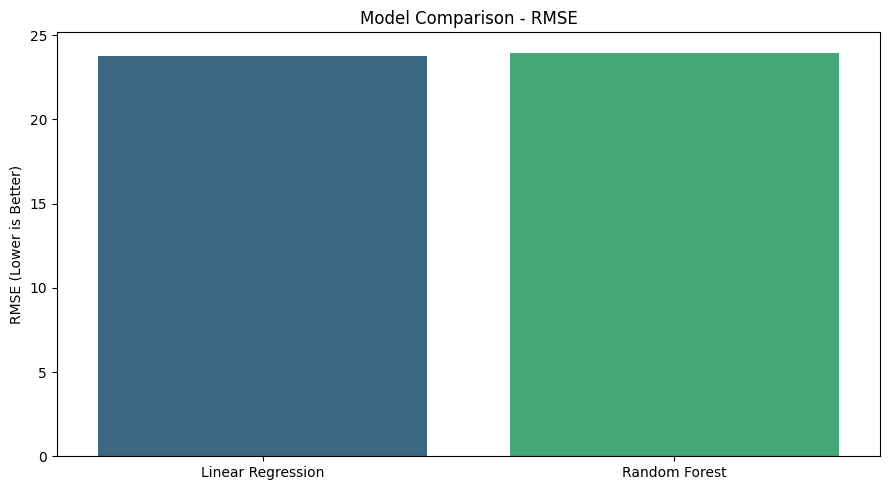

In [44]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE",
    hue="Model",
    palette="viridis",
    legend=False,
    ax=ax
)

ax.set_title("Model Comparison - RMSE")
ax.set_ylabel("RMSE (Lower is Better)")
ax.set_xlabel("")

plt.tight_layout()
plt.show()


In [45]:

from pyspark.sql import functions as F
from pyspark.sql.types import (
    ArrayType, StructType, StructField,
    IntegerType, StringType
)

# Define genres JSON schema
genre_schema = ArrayType(
    StructType([
        StructField("id", IntegerType()),
        StructField("name", StringType())
    ])
)

# Extract genres from JSON
genres_df = clean_df.withColumn(
    "genres_array",
    F.from_json(F.col("genres"), genre_schema)
)

# Display extracted genres
genres_df.select(
    "title",
    "genres_array"
).show(5, truncate=False)


+---------------+-------------------------------------------------------+
|title          |genres_array                                           |
+---------------+-------------------------------------------------------+
|Four Rooms     |[{80, Crime}, {35, Comedy}]                            |
|Star Wars      |[{12, Adventure}, {28, Action}, {878, Science Fiction}]|
|Finding Nemo   |[{16, Animation}, {10751, Family}]                     |
|Forrest Gump   |[{35, Comedy}, {18, Drama}, {10749, Romance}]          |
|American Beauty|[{18, Drama}]                                          |
+---------------+-------------------------------------------------------+
only showing top 5 rows


In [46]:

# Extract genres from training data
train_genres = train_df.withColumn(
    "genres_array",
    F.from_json("genres", genre_schema)
)

# Find top 10 genres
top_genres_rows = (
    train_genres
    .select(F.explode("genres_array").alias("genre"))
    .groupBy(F.col("genre.name").alias("name"))
    .count()
    .orderBy(F.desc("count"), F.asc("name"))
    .limit(10)
    .collect()
)

top_genres = [row["name"] for row in top_genres_rows]

print("Top 10 Genres:")
print(top_genres)


Top 10 Genres:
['Drama', 'Comedy', 'Thriller', 'Action', 'Romance', 'Adventure', 'Crime', 'Science Fiction', 'Family', 'Horror']


In [47]:

from pyspark.ml.feature import StringIndexer, OneHotEncoder

# Create genre features
def add_genre_features(df):
    df = df.withColumn(
        "genres_array",
        F.from_json("genres", genre_schema)
    )

    genre_names = F.transform(
        F.col("genres_array"),
        lambda x: x["name"]
    )

    for i, genre in enumerate(top_genres):
        df = df.withColumn(
            f"genre_{i}",
            F.when(
                F.array_contains(genre_names, genre), 1.0
            ).otherwise(0.0)
        )

    return df

train_fe = add_genre_features(train_df)
test_fe = add_genre_features(test_df)

# Add missing budget indicator
train_fe = train_fe.withColumn(
    "budget_missing",
    F.col("budget").isNull().cast("double")
)

test_fe = test_fe.withColumn(
    "budget_missing",
    F.col("budget").isNull().cast("double")
)

# Handle missing language
train_fe = train_fe.fillna({
    "original_language": "unknown"
})

test_fe = test_fe.fillna({
    "original_language": "unknown"
})

# Encode language
language_indexer = StringIndexer(
    inputCol="original_language",
    outputCol="language_index",
    handleInvalid="keep"
)

language_model = language_indexer.fit(train_fe)

train_fe = language_model.transform(train_fe)
test_fe = language_model.transform(test_fe)

encoder = OneHotEncoder(
    inputCols=["language_index"],
    outputCols=["language_encoded"],
    handleInvalid="keep"
)

encoder_model = encoder.fit(train_fe)

train_fe = encoder_model.transform(train_fe)
test_fe = encoder_model.transform(test_fe)

print("Feature Engineering Completed!")


Feature Engineering Completed!


In [48]:

from pyspark.ml.feature import VectorAssembler

advanced_features = [
    "budget_imputed",
    "runtime_imputed",
    "release_year",
    "budget_missing"
] + [f"genre_{i}" for i in range(len(top_genres))] + [
    "language_encoded"
]

advanced_assembler = VectorAssembler(
    inputCols=advanced_features,
    outputCol="advanced_features"
)

train_advanced = advanced_assembler.transform(train_fe)
test_advanced = advanced_assembler.transform(test_fe)

print("Number of feature columns:", len(advanced_features))

train_advanced.select(
    "title",
    "advanced_features",
    "popularity"
).show(5, truncate=False)


Number of feature columns: 15
+-------------------------------------------------+----------------------------------------------+----------+
|title                                            |advanced_features                             |popularity|
+-------------------------------------------------+----------------------------------------------+----------+
|The Blood of My Brother: A Story of Death in Iraq|(50,[0,1,2,3,14],[2.3E7,90.0,2005.0,1.0,1.0]) |0.005256  |
|Iguana                                           |(50,[0,1,2,3,14],[2.3E7,88.0,1988.0,1.0,1.0]) |0.214704  |
|Sparkler                                         |(50,[0,1,2,3,14],[2.3E7,96.0,1999.0,1.0,1.0]) |0.547654  |
|Harrison Montgomery                              |(50,[0,1,2,3,14],[2.3E7,104.0,2008.0,1.0,1.0])|0.006943  |
|Gory Gory Hallelujah                             |(50,[0,1,2,3,14],[2.3E7,104.0,2003.0,1.0,1.0])|0.033883  |
+-------------------------------------------------+---------------------------------------

In [49]:

from pyspark.ml.regression import LinearRegression

advanced_lr = LinearRegression(
    featuresCol="advanced_features",
    labelCol="popularity",
    predictionCol="prediction",
    maxIter=100,
    regParam=0.1
)

advanced_lr_model = advanced_lr.fit(train_advanced)

advanced_lr_predictions = advanced_lr_model.transform(
    test_advanced
)

print("Advanced Linear Regression Trained!")


Advanced Linear Regression Trained!


In [50]:

from pyspark.ml.regression import RandomForestRegressor

advanced_rf = RandomForestRegressor(
    featuresCol="advanced_features",
    labelCol="popularity",
    predictionCol="prediction",
    numTrees=100,
    maxDepth=8,
    seed=42
)

advanced_rf_model = advanced_rf.fit(train_advanced)

advanced_rf_predictions = advanced_rf_model.transform(
    test_advanced
)

print("Advanced Random Forest Trained!")


Advanced Random Forest Trained!


In [51]:

import pandas as pd

# Evaluate advanced models
advanced_lr_rmse = evaluator_rmse.evaluate(
    advanced_lr_predictions
)
advanced_lr_mae = evaluator_mae.evaluate(
    advanced_lr_predictions
)
advanced_lr_r2 = evaluator_r2.evaluate(
    advanced_lr_predictions
)

advanced_rf_rmse = evaluator_rmse.evaluate(
    advanced_rf_predictions
)
advanced_rf_mae = evaluator_mae.evaluate(
    advanced_rf_predictions
)
advanced_rf_r2 = evaluator_r2.evaluate(
    advanced_rf_predictions
)

# Comparison table
comparison = pd.DataFrame({
    "Model": [
        "Baseline Linear Regression",
        "Baseline Random Forest",
        "Advanced Linear Regression",
        "Advanced Random Forest"
    ],
    "RMSE": [
        lr_rmse, rf_rmse,
        advanced_lr_rmse, advanced_rf_rmse
    ],
    "MAE": [
        lr_mae, rf_mae,
        advanced_lr_mae, advanced_rf_mae
    ],
    "R2": [
        lr_r2, rf_r2,
        advanced_lr_r2, advanced_rf_r2
    ]
})

display(comparison.round(4))


,Model,RMSE,MAE,R2
0,Baseline Linear Regression,23.7761,14.2908,0.2606
1,Baseline Random Forest,23.9736,13.2738,0.2482
2,Advanced Linear Regression,22.8037,13.0481,0.3198
3,Advanced Random Forest,22.6143,12.6612,0.3311
